In [1]:
import os
import cv2
import random
import pickle
import numpy as np
from tqdm import tqdm
import mediapipe as mp
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from collections import defaultdict
from collections import defaultdict
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

2025-03-11 01:29:07.077132: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-11 01:29:07.115173: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1741674547.145864  313991 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1741674547.160853  313991 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-11 01:29:07.204672: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
class Config():
    def __init__(self):        
        self.frame_l = 32 # the length of frames
        self.joint_n = 33 # the number of joints
        self.joint_d = 3 # the dimension of classes        
        self.data_dir = r'skeletal_clips'
        self.save_dir = r'data'

C = Config()

In [3]:
def process_video(video_path, holistic, output_folder):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Failed to open video file {video_path}")
        return

    # Initialize an empty list to store frame coordinates
    video_coords = []

    # Process each frame in the video
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Flip the frame horizontally for a mirrored view
        frame = cv2.flip(frame, 1)

        # Convert the BGR image to RGB
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Process the frame with MediaPipe Holistic
        results = holistic.process(rgb_frame)

        # Extract and store the coordinate data
        if results.pose_landmarks:
            frame_coords = []
            for landmark in results.pose_landmarks.landmark:
                # Store the normalized coordinates (x, y, z) as a list
                frame_coords.append([landmark.x, landmark.y, landmark.z])
            # Append the coordinates of this frame to the video_coords list
            video_coords.append(frame_coords)

    # Convert the list of frame coordinates into a numpy array
    video_coords_array = np.array(video_coords)

    # Save the numpy array of frame coordinates
    filename = os.path.splitext(os.path.basename(video_path))[0] + ".npy"
    output_path = os.path.join(output_folder, filename)
    np.save(output_path, video_coords_array)

    # Release resources
    cap.release()

def process_video_clips(input_folder, output_info_file, output_folder):
    # Initialize MediaPipe Holistic
    mp_holistic = mp.solutions.holistic
    holistic = mp_holistic.Holistic(static_image_mode=False)

    # Create or open the output info file
    with open(output_info_file, "w") as info_file:
        #info_file.write("Serial Number\tAction\tFilename\n")

        # Process each video clip in the input folder
        serial_number = 1
        for filename in os.listdir(input_folder):
            if filename.endswith(".mp4"):
                video_path = os.path.join(input_folder, filename)
                # Extract action name from video file name
                action_name = filename.split("_")[1]  # Assuming action name is after the first underscore
                # Write serial number, action, and filename to info file
                info_file.write(f"{serial_number}\t{action_name}\t{str(filename).split('.')[0]+'.npy'}\n")
                
                process_video(video_path, holistic, output_folder)
                serial_number += 1

if __name__ == "__main__":
    input_folder = r"sliced_clips"  # Folder containing sliced video clips
    output_info_file = "dataset_info.txt"
    output_folder = r"skeletal_clips"
    process_video_clips(input_folder, output_info_file,output_folder)


libEGL warning: MESA-LOADER: failed to open zink: /usr/lib/dri/zink_dri.so: cannot open shared object file: No such file or directory (search paths /usr/lib/x86_64-linux-gnu/dri:\$${ORIGIN}/dri:/usr/lib/dri, suffix _dri)

libEGL warning: MESA-LOADER: failed to open swrast: /usr/lib/dri/swrast_dri.so: cannot open shared object file: No such file or directory (search paths /usr/lib/x86_64-linux-gnu/dri:\$${ORIGIN}/dri:/usr/lib/dri, suffix _dri)

libEGL warning: MESA-LOADER: failed to open zink: /usr/lib/dri/zink_dri.so: cannot open shared object file: No such file or directory (search paths /usr/lib/x86_64-linux-gnu/dri:\$${ORIGIN}/dri:/usr/lib/dri, suffix _dri)

libEGL warning: MESA-LOADER: failed to open swrast: /usr/lib/dri/swrast_dri.so: cannot open shared object file: No such file or directory (search paths /usr/lib/x86_64-linux-gnu/dri:\$${ORIGIN}/dri:/usr/lib/dri, suffix _dri)

libEGL warning: MESA-LOADER: failed to open zink: /usr/lib/dri/zink_dri.so: cannot open shared object fi

In [18]:
# Function to read dataset info from file
def read_dataset_info(file_path):
    dataset_info = []
    with open(file_path, "r") as info_file:
        for line in info_file:
            # Strip any leading or trailing whitespace and split the line by tabs
            info = line.strip().split("\t")
            if info[1] != "HandAction":
                dataset_info.append(info)
    return dataset_info

# Function to perform label encoding
def label_encode(dataset_info):
    label_encoder = LabelEncoder()
    labels = [info[1] for info in dataset_info]
    encoded_labels = label_encoder.fit_transform(labels)

    for i, info in enumerate(dataset_info):
        info[1] = encoded_labels[i]
    
    return dataset_info


Hardcoded Label Mapping: {'ArmFlapping': 0, 'HeadBanging': 1, 'Spinning': 2}


In [5]:

# Define the path to the dataset info file
output_info_file = r"dataset_info.txt"

# Load dataset info
dataset_info = read_dataset_info(output_info_file)

# Dictionary to store subjects per class
classwise_subjects = defaultdict(lambda: defaultdict(list))

# Group videos by class and subject
for info in dataset_info:
    class_label = info[1]  # Class (e.g., Spinning, HeadBanging)
    filename = info[2]     # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # e.g., "Spinning_54"
    
    # Store subject-wise video info per class
    classwise_subjects[class_label][subject_id].append(info)

# Initialize train and test sets
train_info = []
test_info = []

# Perform balanced train-test split for each class
random.seed(42)  # Ensure reproducibility

for class_label, subjects in classwise_subjects.items():
    unique_subjects = list(subjects.keys())
    random.shuffle(unique_subjects)  # Shuffle subjects within each class
    split_idx = int(0.8 * len(unique_subjects))  # 80% Train, 20% Test

    train_subjects = set(unique_subjects[:split_idx])
    test_subjects = set(unique_subjects[split_idx:])

    # Assign videos from subjects to train and test sets
    train_info.extend([vid for subj in train_subjects for vid in subjects[subj]])
    test_info.extend([vid for subj in test_subjects for vid in subjects[subj]])

# Define paths for the output files
train_info_file = "train_dataset_info.txt"
test_info_file = "test_dataset_info.txt"

# Save training dataset info to a text file
with open(train_info_file, "w") as train_file:
    for info in train_info:
        train_file.write("\t".join(map(str, info)) + "\n")

# Save test dataset info to a text file
with open(test_info_file, "w") as test_file:
    for info in test_info:
        test_file.write("\t".join(map(str, info)) + "\n")

print(f"Train and test splits saved successfully!\nTrain: {len(train_info)} videos\nTest: {len(test_info)} videos")


Train and test splits saved successfully!
Train: 309 videos
Test: 63 videos


(array([153.,   0.,   0.,   0.,   0., 106.,   0.,   0.,   0., 113.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

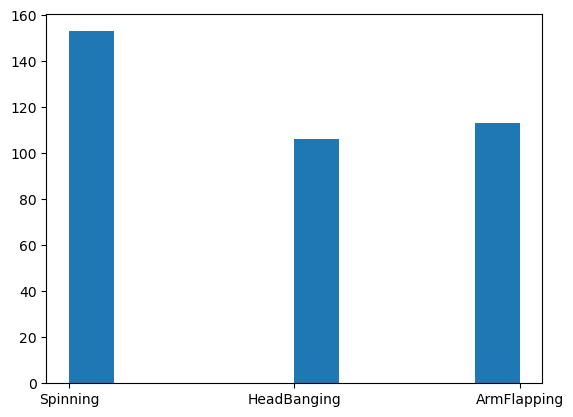

In [6]:
labels = read_dataset_info(output_info_file)
labels = [labels[i][1] for i in range(len(labels))]
plt.hist(labels)


In [7]:
# Read training dataset info
train_info_file = "train_dataset_info.txt"
train_list = label_encode(read_dataset_info(train_info_file))

# Read test dataset info
test_info_file = "test_dataset_info.txt"
test_list = label_encode(read_dataset_info(test_info_file))

(array([100.,   0.,   0.,   0.,   0.,  89.,   0.,   0.,   0., 120.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

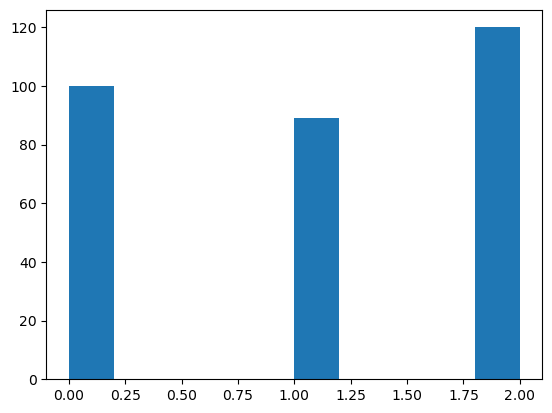

In [8]:

labels = [train_list[i][1] for i in range(len(train_list))]
plt.hist(labels)

(array([13.,  0.,  0.,  0.,  0., 17.,  0.,  0.,  0., 33.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

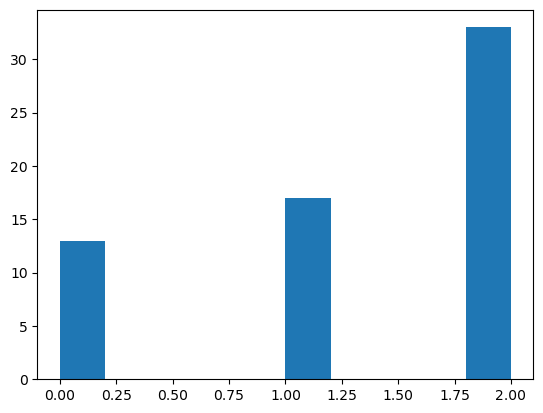

In [9]:
labels = [test_list[i][1] for i in range(len(test_list))]
plt.hist(labels)

In [10]:
print(test_list[1])

['98', 2, 'v_Spinning_07_action_seg_slice_2.npy']


In [11]:
# Define augmentation functions
def translate_skeleton(skeleton, max_translation=0.05):
    """Translate skeleton by a random amount."""
    translation = np.random.uniform(-max_translation, max_translation, size=(1, skeleton.shape[1], skeleton.shape[2]))
    return skeleton + translation

def scale_skeleton(skeleton, scale_range=(0.9, 1.1)):
    """Scale skeleton by a random factor."""
    scale_factor = np.random.uniform(*scale_range, size=(1, 1, skeleton.shape[2]))
    return skeleton * scale_factor

def rotate_skeleton(skeleton, max_angle=15):
    """Rotate skeleton by a random angle around the Z-axis."""
    angle = np.radians(np.random.uniform(-max_angle, max_angle))
    rotation_matrix = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle), np.cos(angle), 0],
        [0, 0, 1]
    ])
    return np.dot(skeleton, rotation_matrix)

def apply_augmentations(skeleton, num_augments=5):
    augmented_skeletons = []

    if skeleton.size == 0:
        print("Warning: Empty skeleton array; no augmentations applied.")
        return augmented_skeletons

    #print("Original skeleton shape:", skeleton.shape)

    for _ in range(num_augments):
        augmented_skeleton = skeleton.copy()
        augmented_skeleton = translate_skeleton(augmented_skeleton)
        augmented_skeleton = scale_skeleton(augmented_skeleton)
        augmented_skeleton = rotate_skeleton(augmented_skeleton)
        augmented_skeletons.append(augmented_skeleton)

    return augmented_skeletons

In [12]:
# # Function to process multiple video clips
# def Augu_video_clips(data_info, train_info, test_info):
        
#     # Apply augmentations only to the training set
#     for i, (serial_number, action_name, skel) in enumerate(test_info):
#         skeleton_path =os.path.join(C.data_dir, str(skel))
#         try:
#             skeleton = np.load(skeleton_path).astype('float32')
#             np.save(os.path.join(C.save_dir, str(skel)), skeleton)
#         except Exception as e:
#             print(f"An error occurred while processing {skel}: {e}")
        
#         if action_name == 2:
#             augmented_skeletons = apply_augmentations(skeleton, 7)
#         else:
#             augmented_skeletons = apply_augmentations(skeleton, 7)
#         for j, augmented_skeleton in enumerate(augmented_skeletons):
#             aug_npy_filename = f"{action_name}_aug_{i}_{j}.npy"  # Adjust filename for uniqueness
#             np.save(os.path.join(C.save_dir, aug_npy_filename), augmented_skeleton)
#             # Write info about the augmented data to the file
#             with open(test_info_file, "a") as info_file:  # Append to the existing info file
#                 info_file.write(f"{serial_number}\t{action_name}\t{aug_npy_filename}\n")

# if __name__ == "__main__":      
#     #Augument data after splitting into train and test
#     # Augu_video_clips(dataset_info, train_info, test_info)


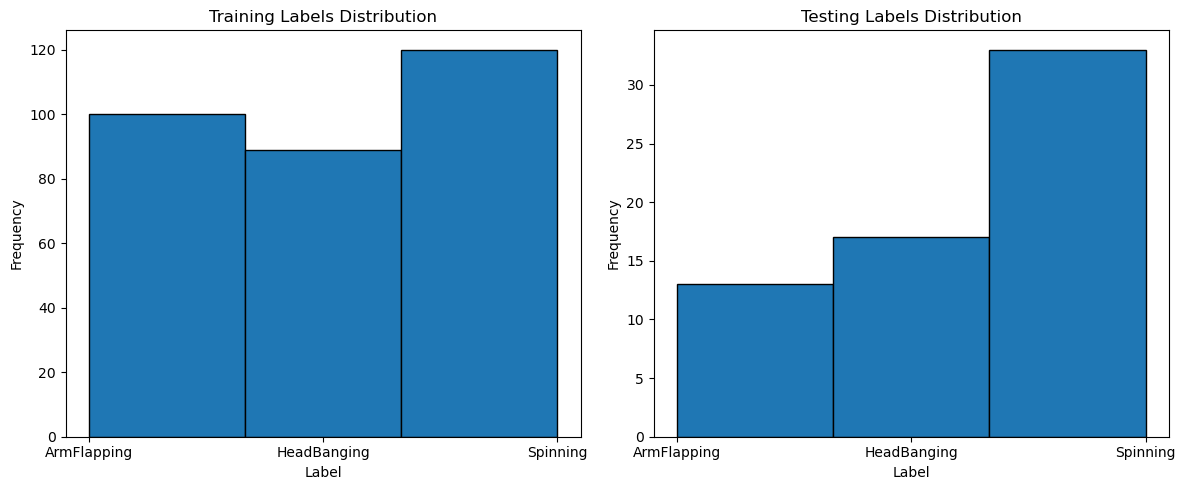

In [13]:
labels_train = read_dataset_info(train_info_file)
labels_test = read_dataset_info(test_info_file)

labels_train = [labels_train[i][1] for i in range(len(labels_train))]
labels_test = [labels_test[i][1] for i in range(len(labels_test))]

# Create subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Plot histogram for the training labels
axs[0].hist(sorted(labels_train), bins=len(set(labels_train)), edgecolor='black')
axs[0].set_title('Training Labels Distribution')
axs[0].set_xlabel('Label')
axs[0].set_ylabel('Frequency')

# Plot histogram for the testing labels
axs[1].hist(sorted(labels_test), bins=len(set(labels_test)), edgecolor='black')
axs[1].set_title('Testing Labels Distribution')
axs[1].set_xlabel('Label')
axs[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [14]:
Train = {}
Train['pose'] = []
Train['label'] = []

for i in tqdm(range(len(train_list))):
    label = train_list[i][1]
    skeletons = train_list[i][2]
    
    skeleton_path =os.path.join(C.data_dir, str(skeletons))
    
    try:
        p = np.load(skeleton_path).astype('float32')
        for j in range(p.shape[1]):
            p[:, j] = medfilt(p[:, j])
        
        Train['pose'].append(p)
        Train['label'].append(label)
    except Exception as e:
        print(f"An error occurred while processing {skeletons}: {e}")

    

100%|█████████████████████████████████████████████████████████████████████| 309/309 [00:00<00:00, 1137.93it/s]


In [15]:
pickle.dump(Train, open("train.pkl", "wb"))

In [16]:
Test = {}
Test['pose'] = []
Test['label'] = []

for i in tqdm(range(len(test_list))):
    label = test_list[i][1]
    skeletons = test_list[i][2]
    
    skeleton_path = os.path.join(C.data_dir, str(skeletons))
    
    try:
        p = np.load(skeleton_path).astype('float32')
        for j in range(p.shape[1]):
            p[:, j] = medfilt(p[:, j])
        
        Test['pose'].append(p)
        Test['label'].append(label)
    except Exception as e:
        print(f"An error occurred while processing {skeletons}: {e}")


100%|███████████████████████████████████████████████████████████████████████| 63/63 [00:00<00:00, 1087.27it/s]


In [17]:
pickle.dump(Test, open("test.pkl", "wb"))